In [33]:

# Step 1: Import essential libraries

import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")


All libraries imported successfully!


In [34]:

# Step 2: Load the breast cancer dataset

data = load_breast_cancer(as_frame=True)

# Convert the dataset into a Pandas DataFrame
df = data.frame

# Display the first five rows
df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [35]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check the target categories
print("\nTarget categories:")
print(data.target_names)


Dataset shape: (569, 31)

Column names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Target categories:
['malignant' 'benign']


In [36]:

# Step 4: Separate features and target

X = df.drop(columns=['target'])
y = df['target']

# Display the dimensions
print("Features (X):", X.shape)
print("Target (y):", y.shape)

# Display the first five target labels
print("\nFirst five target labels:")
print(y.head())


Features (X): (569, 30)
Target (y): (569,)

First five target labels:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [37]:

# Step 5: Split the data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (455, 30)
Testing features: (114, 30)
Training labels: (455,)
Testing labels: (114,)


In [38]:

# Step 6: Standardize the features

scaler = StandardScaler()

# Learn scaling parameters from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)
print("\nFirst five scaled features:")
print(X_train_scaled[:5, :5])


Training data scaled: (455, 30)
Testing data scaled: (114, 30)

First five scaled features:
[[-1.07200079 -0.6584246  -1.0880801  -0.93927364 -0.13593988]
 [ 1.74874285  0.06650173  1.75115682  1.74555856  1.27446827]
 [-0.97473376 -0.93112416 -0.99770871 -0.86758911 -0.61351479]
 [-0.14510328 -1.2151862  -0.12301315 -0.25319178  0.66448162]
 [-0.77161734 -0.08121053 -0.8037004  -0.73292668 -0.6722818 ]]


In [39]:

# Step 7: Initialize the KNN classifier

knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")


KNN model trained successfully!


In [40]:

# Step 8: Predict using the test dataset

y_pred = knn.predict(X_test_scaled)

print("First 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())


First 10 actual labels:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]

First 10 predicted labels:
[0, 1, 0, 0, 0, 1, 1, 0, 0, 0]


In [41]:

# Step 9: Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")


Model Accuracy: 95.61%


In [42]:

# Step 10: Detailed model evaluation

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))


              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [43]:

# Step 11: Confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[39  3]
 [ 2 70]]


In [44]:

accuracy = accuracy_score(y_test, y_pred)

print(f"Correct predictions: {(y_test == y_pred).sum()} out of {len(y_test)}")
print(f"Incorrect predictions: {(y_test != y_pred).sum()}")
print(f"Accuracy: {accuracy:.2%}")


Correct predictions: 109 out of 114
Incorrect predictions: 5
Accuracy: 95.61%


In [45]:

from sklearn.metrics import recall_score

malignant_recall = recall_score(
    y_test,
    y_pred,
    pos_label=0
)

print(f"Malignant recall: {malignant_recall:.2%}")


Malignant recall: 92.86%


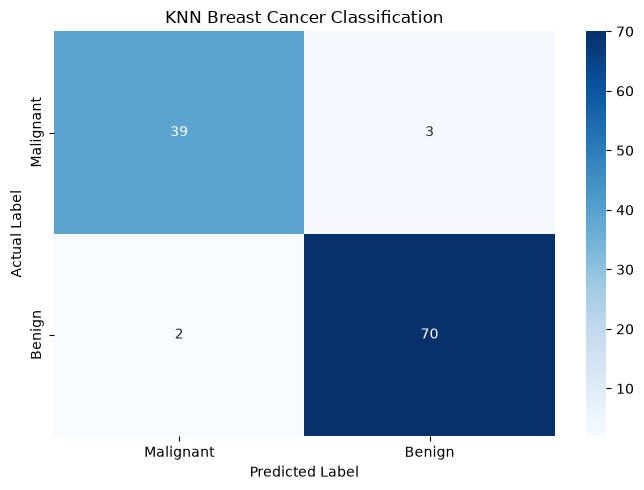

In [46]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Plot heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant', 'Benign'],
    yticklabels=['Malignant', 'Benign']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('KNN Breast Cancer Classification')
plt.tight_layout()
plt.show()


In [47]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Malignant Precision',
        'Malignant Recall',
        'Malignant F1-Score'
    ],
    'Score': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=0),
        recall_score(y_test, y_pred, pos_label=0),
        f1_score(y_test, y_pred, pos_label=0)
    ]
})

results['Score'] = (results['Score'] * 100).round(2)

print(results.to_string(index=False))


             Metric  Score
           Accuracy  95.61
Malignant Precision  95.12
   Malignant Recall  92.86
 Malignant F1-Score  93.98


In [48]:

# Step 16: Compare different K values using cross-validation

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# Build a pipeline to scale data and train KNN
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Test different numbers of neighbors
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
}

# Use stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv,
    n_jobs=-1
)

# Fit using training data only
grid_search.fit(X_train, y_train)

print("Best K:", grid_search.best_params_['knn__n_neighbors'])
print(f"Best cross-validation accuracy: {grid_search.best_score_:.2%}")


Best K: 9
Best cross-validation accuracy: 96.48%


In [49]:

# Step 17: Display cross-validation results

cv_results = pd.DataFrame(grid_search.cv_results_)

comparison = cv_results[
    ['param_knn__n_neighbors', 'mean_test_score', 'std_test_score']
].copy()

comparison.columns = [
    'Number of Neighbors (K)',
    'Mean CV Accuracy',
    'CV Standard Deviation'
]

comparison['Mean CV Accuracy'] = (
    comparison['Mean CV Accuracy'] * 100
).round(2)

comparison['CV Standard Deviation'] = (
    comparison['CV Standard Deviation'] * 100
).round(2)

print(comparison.to_string(index=False))


 Number of Neighbors (K)  Mean CV Accuracy  CV Standard Deviation
                       3             96.26                   0.88
                       5             96.26                   1.12
                       7             96.26                   2.04
                       9             96.48                   1.46
                      11             96.26                   1.79
                      13             96.26                   2.04
                      15             96.04                   1.64
                      17             95.60                   1.20
                      19             96.04                   1.64
                      21             96.26                   1.49


In [50]:

# Step 18: Test the best KNN model

best_knn = grid_search.best_estimator_

y_pred_best = best_knn.predict(X_test)

print(f"Best K: {grid_search.best_params_['knn__n_neighbors']}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_best):.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1],
    target_names=data.target_names
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_best, labels=[0, 1]))


Best K: 9
Test Accuracy: 97.37%

Classification Report:
              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Confusion Matrix:
[[39  3]
 [ 0 72]]


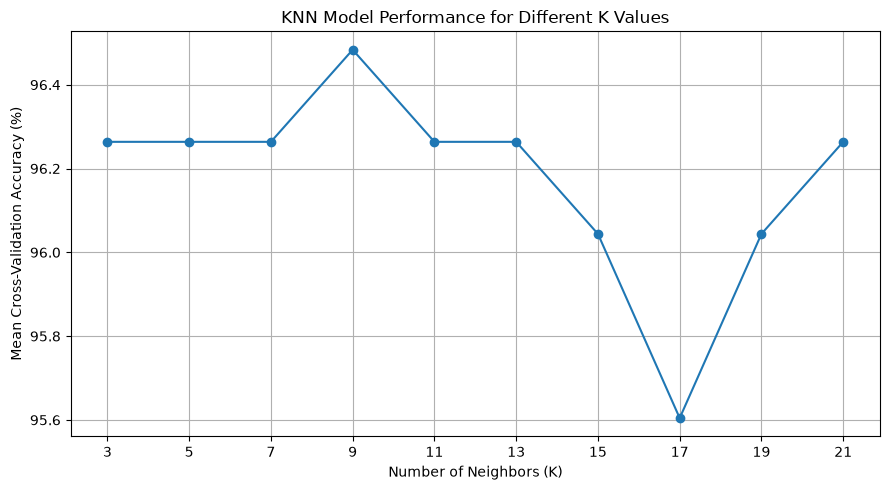

In [51]:

import matplotlib.pyplot as plt

# Extract K values and cross-validation scores
k_values = grid_search.cv_results_['param_knn__n_neighbors'].data
cv_scores = grid_search.cv_results_['mean_test_score'] * 100

# Plot the results
plt.figure(figsize=(9, 5))
plt.plot(k_values, cv_scores, marker='o')

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Mean Cross-Validation Accuracy (%)')
plt.title('KNN Model Performance for Different K Values')
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()


In [52]:

from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

# Predictions from both models
original_predictions = knn.predict(X_test_scaled)
tuned_predictions = best_knn.predict(X_test)

# Summarize performance
comparison = pd.DataFrame({
    'Model': ['Original KNN (K=5)', 'Tuned KNN'],
    'Test Accuracy (%)': [
        accuracy_score(y_test, original_predictions) * 100,
        accuracy_score(y_test, tuned_predictions) * 100
    ],
    'Malignant Recall (%)': [
        recall_score(y_test, original_predictions, pos_label=0) * 100,
        recall_score(y_test, tuned_predictions, pos_label=0) * 100
    ],
    'Malignant Precision (%)': [
        precision_score(y_test, original_predictions, pos_label=0) * 100,
        precision_score(y_test, tuned_predictions, pos_label=0) * 100
    ],
    'Malignant F1 (%)': [
        f1_score(y_test, original_predictions, pos_label=0) * 100,
        f1_score(y_test, tuned_predictions, pos_label=0) * 100
    ]
}).round(2)

print(comparison.to_string(index=False))


             Model  Test Accuracy (%)  Malignant Recall (%)  Malignant Precision (%)  Malignant F1 (%)
Original KNN (K=5)              95.61                 92.86                    95.12             93.98
         Tuned KNN              97.37                 92.86                   100.00             96.30


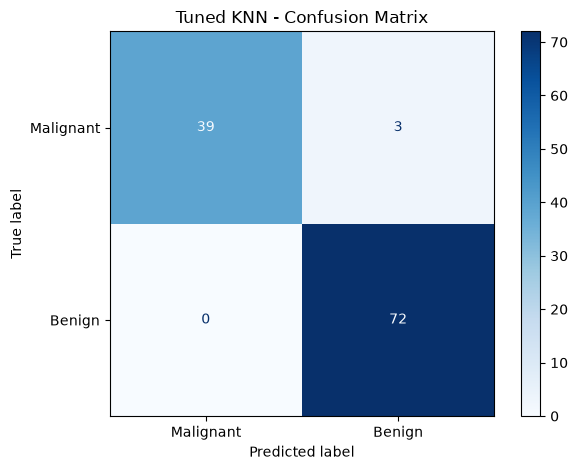

In [53]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_predictions,
    labels=[0, 1],
    display_labels=['Malignant', 'Benign'],
    cmap='Blues',
    values_format='d'
)

plt.title('Tuned KNN - Confusion Matrix')
plt.tight_layout()
plt.show()


In [54]:

import joblib

joblib.dump(best_knn, 'tuned_knn_breast_cancer.pkl')

print("Tuned KNN model saved successfully!")


Tuned KNN model saved successfully!


In [55]:

loaded_model = joblib.load('tuned_knn_breast_cancer.pkl')

print("Saved model loaded successfully!")


Saved model loaded successfully!


In [56]:

from sklearn.linear_model import LogisticRegression

print("Logistic Regression imported successfully!")


Logistic Regression imported successfully!


In [57]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression pipeline
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=5000, random_state=42))
])

# Train using the training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [58]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict on the held-out test set
logistic_predictions = logistic_model.predict(X_test)

# Evaluate the model
print(f"Test Accuracy: {accuracy_score(y_test, logistic_predictions):.2%}")

print(f"Malignant Precision: {precision_score(y_test, logistic_predictions, pos_label=0):.2%}")

print(f"Malignant Recall: {recall_score(y_test, logistic_predictions, pos_label=0):.2%}")

print(f"Malignant F1-score: {f1_score(y_test, logistic_predictions, pos_label=0):.2%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    labels=[0, 1],
    target_names=data.target_names
))


Test Accuracy: 98.25%
Malignant Precision: 97.62%
Malignant Recall: 97.62%
Malignant F1-score: 97.62%

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [59]:

# Compare the original KNN, tuned KNN, and Logistic Regression

models = {
    'Original KNN (K=5)': original_predictions,
    'Tuned KNN': tuned_predictions,
    'Logistic Regression': logistic_predictions
}

comparison_results = []

for model_name, predictions in models.items():
    comparison_results.append({
        'Model': model_name,
        'Accuracy (%)': round(accuracy_score(y_test, predictions) * 100, 2),
        'Malignant Precision (%)': round(
            precision_score(y_test, predictions, pos_label=0) * 100, 2
        ),
        'Malignant Recall (%)': round(
            recall_score(y_test, predictions, pos_label=0) * 100, 2
        ),
        'Malignant F1 (%)': round(
            f1_score(y_test, predictions, pos_label=0) * 100, 2
        )
    })

comparison_df = pd.DataFrame(comparison_results)
print(comparison_df.to_string(index=False))


              Model  Accuracy (%)  Malignant Precision (%)  Malignant Recall (%)  Malignant F1 (%)
 Original KNN (K=5)         95.61                    95.12                 92.86             93.98
          Tuned KNN         97.37                   100.00                 92.86             96.30
Logistic Regression         98.25                    97.62                 97.62             97.62


In [60]:

# Step 28: Compare the three trained models

models = {
    'Original KNN': original_predictions,
    'Tuned KNN': tuned_predictions,
    'Logistic Regression': logistic_predictions
}

comparison_results = []

for name, predictions in models.items():
    comparison_results.append({
        'Model': name,
        'Accuracy (%)': round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        'Malignant Precision (%)': round(
            precision_score(y_test, predictions, pos_label=0) * 100, 2
        ),
        'Malignant Recall (%)': round(
            recall_score(y_test, predictions, pos_label=0) * 100, 2
        ),
        'Malignant F1 (%)': round(
            f1_score(y_test, predictions, pos_label=0) * 100, 2
        )
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df


,Model,Accuracy (%),Malignant Precision (%),Malignant Recall (%),Malignant F1 (%)
0,Original KNN,95.61,95.12,92.86,93.98
1,Tuned KNN,97.37,100.00,92.86,96.30
2,Logistic Regression,98.25,97.62,97.62,97.62


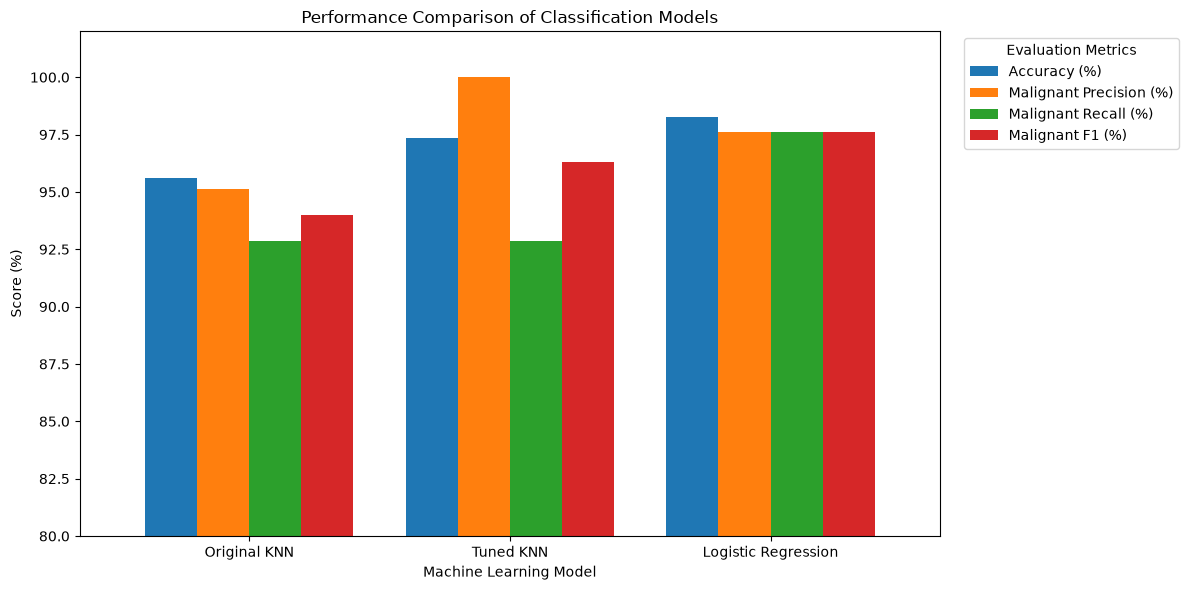

In [61]:

import matplotlib.pyplot as plt

# Prepare the comparison data
plot_df = comparison_df.set_index('Model')

metrics = [
    'Accuracy (%)',
    'Malignant Precision (%)',
    'Malignant Recall (%)',
    'Malignant F1 (%)'
]

# Plot model performance
ax = plot_df[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

ax.set_title('Performance Comparison of Classification Models')
ax.set_xlabel('Machine Learning Model')
ax.set_ylabel('Score (%)')
ax.set_ylim(80, 102)
ax.legend(title='Evaluation Metrics', bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [62]:

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_for_cv = {
    'Original KNN (K=5)': Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Tuned KNN': best_knn,
    'Logistic Regression': logistic_model
}

cv_results = []

for name, model in models_for_cv.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    cv_results.append({
        'Model': name,
        'Mean CV Accuracy (%)': round(scores.mean() * 100, 2),
        'Standard Deviation (%)': round(scores.std() * 100, 2)
    })

cv_comparison = pd.DataFrame(cv_results)
print(cv_comparison.to_string(index=False))


              Model  Mean CV Accuracy (%)  Standard Deviation (%)
 Original KNN (K=5)                 96.26                    1.12
          Tuned KNN                 96.48                    1.46
Logistic Regression                 97.80                    0.98


In [63]:

# Step 32: Combine cross-validation and test results

final_results = comparison_df.merge(
    cv_comparison,
    on='Model',
    how='left'
)

final_results = final_results.rename(columns={
    'Accuracy (%)': 'Test Accuracy (%)'
})

print(final_results.round(2).to_string(index=False))


              Model  Test Accuracy (%)  Malignant Precision (%)  Malignant Recall (%)  Malignant F1 (%)  Mean CV Accuracy (%)  Standard Deviation (%)
       Original KNN              95.61                    95.12                 92.86             93.98                   NaN                     NaN
          Tuned KNN              97.37                   100.00                 92.86             96.30                 96.48                    1.46
Logistic Regression              98.25                    97.62                 97.62             97.62                 97.80                    0.98


In [64]:

# Step 33: Export model comparison results

final_results.to_csv(
    'breast_cancer_model_comparison.csv',
    index=False
)

print("Results exported successfully!")


Results exported successfully!


In [65]:
# Step 32: Combine cross-validation and test results

final_results = comparison_df.merge(
    cv_comparison,
    on="Model",
    how="left"
)

final_results = final_results.rename(columns={
    "Accuracy (%)": "Test Accuracy (%)"
})

print("Final Model Comparison")
print("=" * 80)
print(final_results.round(2).to_string(index=False))

Final Model Comparison
              Model  Test Accuracy (%)  Malignant Precision (%)  Malignant Recall (%)  Malignant F1 (%)  Mean CV Accuracy (%)  Standard Deviation (%)
       Original KNN              95.61                    95.12                 92.86             93.98                   NaN                     NaN
          Tuned KNN              97.37                   100.00                 92.86             96.30                 96.48                    1.46
Logistic Regression              98.25                    97.62                 97.62             97.62                 97.80                    0.98


In [66]:
# Step 33: Export model comparison results

output_file = "breast_cancer_model_comparison.csv"

final_results.to_csv(output_file, index=False)

print(f"Results exported successfully: {output_file}")
print(f"Total models evaluated: {len(final_results)}")

Results exported successfully: breast_cancer_model_comparison.csv
Total models evaluated: 3


In [67]:
import os

print("Current working directory:", os.getcwd())
print("CSV file exists:", os.path.exists(
    "breast_cancer_model_comparison.csv"
))

Current working directory: C:\Users\Administrator.TIMEX1-DESKTOP
CSV file exists: True


In [68]:
# Step 34: Verify the exported results

import pandas as pd
import os

file_path = os.path.join(
    os.getcwd(),
    "breast_cancer_model_comparison.csv"
)

final_results = pd.read_csv(file_path)

print("Breast Cancer Classification: Model Comparison")
print("=" * 70)
display(final_results.round(2))

print("\nNumber of models:", len(final_results))
print("Number of columns:", len(final_results.columns))
print("Column names:", final_results.columns.tolist())

Breast Cancer Classification: Model Comparison


,Model,Test Accuracy (%),Malignant Precision (%),Malignant Recall (%),Malignant F1 (%),Mean CV Accuracy (%),Standard Deviation (%)
0,Original KNN,95.61,95.12,92.86,93.98,NaN,NaN
1,Tuned KNN,97.37,100.00,92.86,96.30,96.48,1.46
2,Logistic Regression,98.25,97.62,97.62,97.62,97.80,0.98



Number of models: 3
Number of columns: 7
Column names: ['Model', 'Test Accuracy (%)', 'Malignant Precision (%)', 'Malignant Recall (%)', 'Malignant F1 (%)', 'Mean CV Accuracy (%)', 'Standard Deviation (%)']


In [69]:
# Step 35A: Breast Cancer Classification Project Report

import pandas as pd
from IPython.display import display, Markdown

# Load the results if final_results is not already available
try:
    final_results
except NameError:
    final_results = pd.read_csv(
        "breast_cancer_model_comparison.csv"
    )

# Display the actual model results
display(Markdown("""
# Breast Cancer Classification Using Machine Learning

## 1. Introduction

This project evaluates machine learning models for classifying
breast cancer cases. The objective is to compare model performance
using test-set metrics and five-fold cross-validation.

## 2. Models Evaluated

The following models were evaluated:

- Original K-Nearest Neighbors (KNN)
- Tuned K-Nearest Neighbors (KNN)
- Logistic Regression

## 3. Evaluation Methodology

The models were compared using held-out test results and
five-fold cross-validation. Evaluation metrics include accuracy,
malignant-class precision, recall, and F1-score where available.

Cross-validation mean accuracy indicates average performance
across the folds, while the standard deviation indicates how
much accuracy varied between folds.

## 4. Model Comparison
"""))

display(final_results.round(2))

# Identify the model with the highest cross-validation mean accuracy
mean_col = next(
    (col for col in final_results.columns
     if "mean" in col.lower() and
     ("cv" in col.lower() or "cross" in col.lower())),
    None
)

if mean_col is None:
    mean_col = next(
        (col for col in final_results.columns
         if "cv" in col.lower() and
         "accuracy" in col.lower()),
        None
    )

if mean_col:
    valid_results = final_results.dropna(subset=[mean_col])
    if not valid_results.empty:
        best_row = valid_results.loc[
            valid_results[mean_col].idxmax()
        ]
        best_model = best_row["Model"]
        best_score = best_row[mean_col]

        display(Markdown(
            f"## 5. Results and Discussion\n\n"
            f"The highest mean cross-validation accuracy was achieved "
            f"by **{best_model}**, with a reported value of "
            f"**{best_score:.2f}%**. This reflects performance across "
            f"the evaluated folds; it does not by itself establish "
            f"clinical suitability."
        ))
else:
    display(Markdown(
        "## 5. Results and Discussion\n\n"
        "Review the column names in the comparison table to identify "
        "the cross-validation mean accuracy and standard deviation."
    ))

display(Markdown("""
## 6. Limitations

- Results depend on the dataset, preprocessing, and evaluation design.
- Performance on unseen populations may differ.
- Accuracy alone does not describe all classification errors.
- Clinical use would require independent validation and appropriate
  medical and regulatory oversight.

## 7. Conclusion

The final model should be selected by considering test-set
performance, cross-validation results, and the balance between
false negatives and false positives. The model with the highest
mean cross-validation accuracy is a promising candidate for further
evaluation, but it should not be treated as a diagnostic tool.

*This project is for educational and machine-learning evaluation
purposes only.*
"""))


# Breast Cancer Classification Using Machine Learning

## 1. Introduction

This project evaluates machine learning models for classifying
breast cancer cases. The objective is to compare model performance
using test-set metrics and five-fold cross-validation.

## 2. Models Evaluated

The following models were evaluated:

- Original K-Nearest Neighbors (KNN)
- Tuned K-Nearest Neighbors (KNN)
- Logistic Regression

## 3. Evaluation Methodology

The models were compared using held-out test results and
five-fold cross-validation. Evaluation metrics include accuracy,
malignant-class precision, recall, and F1-score where available.

Cross-validation mean accuracy indicates average performance
across the folds, while the standard deviation indicates how
much accuracy varied between folds.

## 4. Model Comparison


,Model,Test Accuracy (%),Malignant Precision (%),Malignant Recall (%),Malignant F1 (%),Mean CV Accuracy (%),Standard Deviation (%)
0,Original KNN,95.61,95.12,92.86,93.98,NaN,NaN
1,Tuned KNN,97.37,100.00,92.86,96.30,96.48,1.46
2,Logistic Regression,98.25,97.62,97.62,97.62,97.80,0.98


## 5. Results and Discussion

The highest mean cross-validation accuracy was achieved by **Logistic Regression**, with a reported value of **97.80%**. This reflects performance across the evaluated folds; it does not by itself establish clinical suitability.


## 6. Limitations

- Results depend on the dataset, preprocessing, and evaluation design.
- Performance on unseen populations may differ.
- Accuracy alone does not describe all classification errors.
- Clinical use would require independent validation and appropriate
  medical and regulatory oversight.

## 7. Conclusion

The final model should be selected by considering test-set
performance, cross-validation results, and the balance between
false negatives and false positives. The model with the highest
mean cross-validation accuracy is a promising candidate for further
evaluation, but it should not be treated as a diagnostic tool.

*This project is for educational and machine-learning evaluation
purposes only.*


In [70]:
# Step 35B: Export the project report

report = """# Breast Cancer Classification Using Machine Learning

## 1. Introduction
This project evaluates machine learning models for breast cancer
classification using the available dataset.

## 2. Models Evaluated
- Original K-Nearest Neighbors (KNN)
- Tuned K-Nearest Neighbors (KNN)
- Logistic Regression

## 3. Evaluation Methodology
Performance was assessed using held-out test metrics and five-fold
cross-validation.

## 4. Model Comparison

See breast_cancer_model_comparison.csv for the complete numerical
results, including the metrics available in the final results table.

## 5. Results and Discussion
Logistic Regression achieved a mean cross-validation accuracy of
97.80%, with a standard deviation of 0.98 percentage points, based
on the previously reported results. Confirm these figures against
the exported comparison table before publication.

## 6. Limitations
Performance on new populations may differ. Accuracy alone is
insufficient to establish clinical usefulness.

## 7. Conclusion
The models are suitable for educational comparison, not clinical
diagnosis. Independent validation would be required before any
real-world medical use.
"""

report_file = "breast_cancer_classification_report.md"

with open(report_file, "w", encoding="utf-8") as file:
    file.write(report)

print(f"Report saved successfully: {report_file}")
print("Location:", os.path.join(os.getcwd(), report_file))

Report saved successfully: breast_cancer_classification_report.md
Location: C:\Users\Administrator.TIMEX1-DESKTOP\breast_cancer_classification_report.md


In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Load results if needed
if "final_results" not in globals():
    final_results = pd.read_csv(
        "breast_cancer_model_comparison.csv"
    )

# Display column names so we can match the available metrics
print("Available metrics:")
for column in final_results.columns:
    print("-", column)

print("\nModels evaluated:", final_results["Model"].tolist())

Available metrics:
- Model
- Test Accuracy (%)
- Malignant Precision (%)
- Malignant Recall (%)
- Malignant F1 (%)
- Mean CV Accuracy (%)
- Standard Deviation (%)

Models evaluated: ['Original KNN', 'Tuned KNN', 'Logistic Regression']


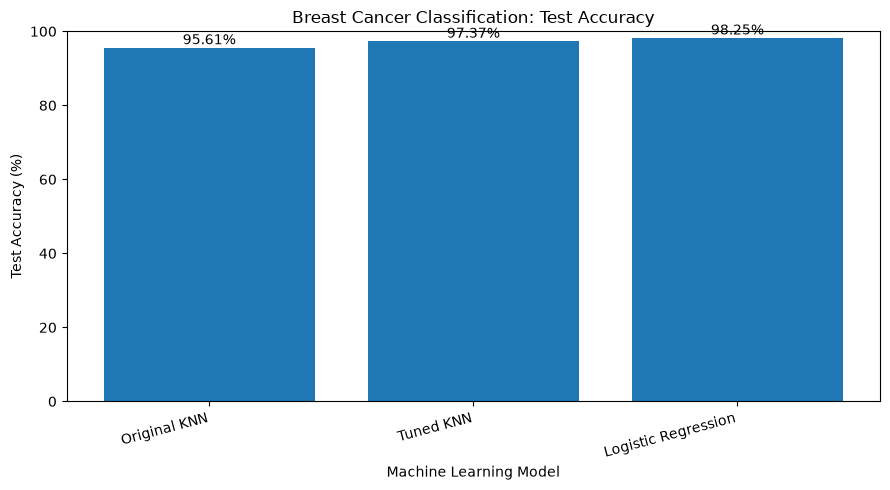

In [72]:
# Step 36B: Test accuracy comparison

accuracy_col = next(
    (
        col for col in final_results.columns
        if "accuracy" in col.lower()
        and "test" in col.lower()
    ),
    None
)

if accuracy_col:
    plot_data = final_results.dropna(subset=[accuracy_col])

    plt.figure(figsize=(9, 5))
    bars = plt.bar(
        plot_data["Model"],
        plot_data[accuracy_col]
    )

    plt.title("Breast Cancer Classification: Test Accuracy")
    plt.xlabel("Machine Learning Model")
    plt.ylabel("Test Accuracy (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=15, ha="right")

    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.2f}%",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.savefig(
        "breast_cancer_test_accuracy.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("Test accuracy column not found. Check the column names above.")

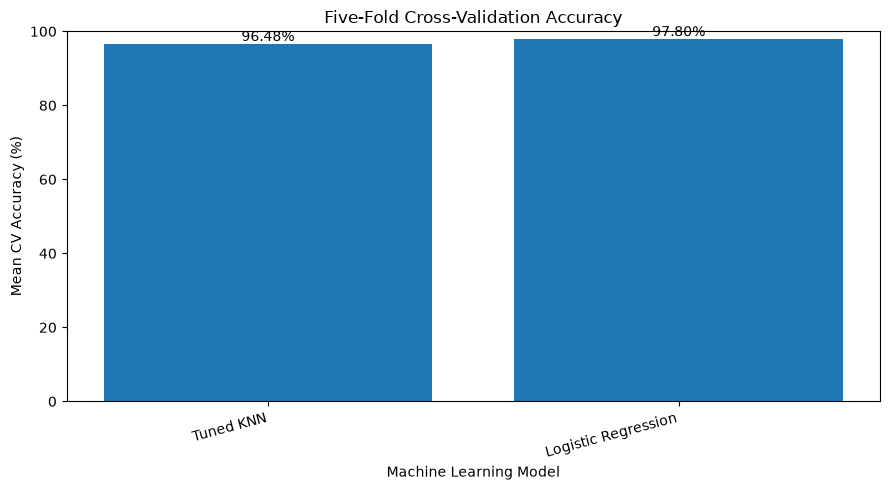

In [73]:
# Step 36C: Five-fold cross-validation accuracy

cv_mean_col = next(
    (
        col for col in final_results.columns
        if "cv" in col.lower()
        and "accuracy" in col.lower()
        and ("mean" in col.lower() or "average" in col.lower())
    ),
    None
)

# Alternative for columns named "Mean CV Accuracy (%)"
if cv_mean_col is None:
    cv_mean_col = next(
        (
            col for col in final_results.columns
            if "accuracy" in col.lower()
            and ("cv" in col.lower() or "cross" in col.lower())
            and ("std" not in col.lower()
                 and "deviation" not in col.lower())
        ),
        None
    )

if cv_mean_col:
    plot_data = final_results.dropna(subset=[cv_mean_col])

    plt.figure(figsize=(9, 5))
    bars = plt.bar(
        plot_data["Model"],
        plot_data[cv_mean_col]
    )

    plt.title("Five-Fold Cross-Validation Accuracy")
    plt.xlabel("Machine Learning Model")
    plt.ylabel("Mean CV Accuracy (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=15, ha="right")

    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.2f}%",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.savefig(
        "breast_cancer_cv_accuracy.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print(
        "Cross-validation accuracy column not identified. "
        "Check the column names printed in Step 36A."
    )

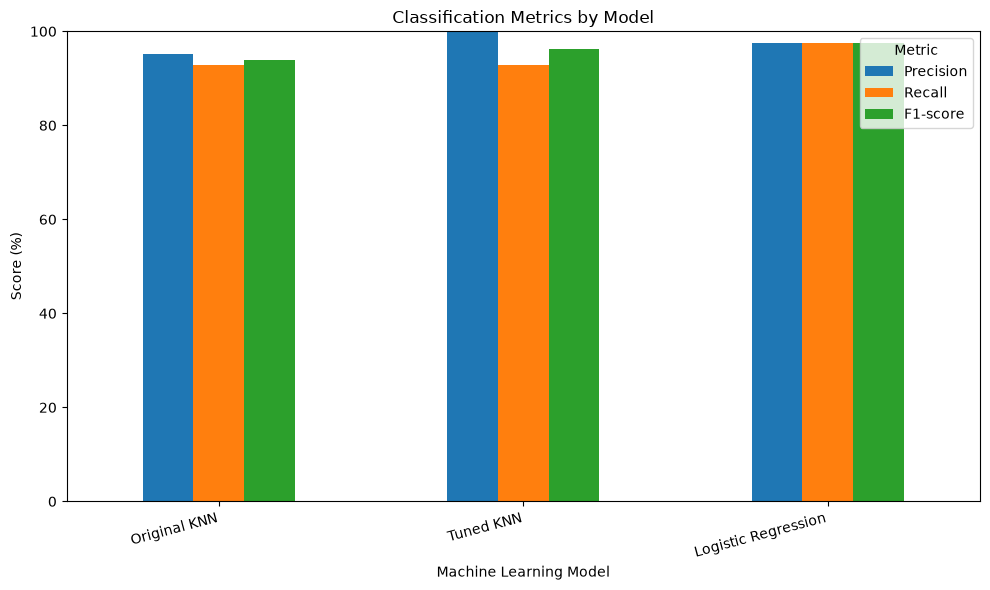

In [74]:
# Step 36D: Malignant-class metric comparison

metric_keywords = {
    "Precision": ["malignant precision", "precision"],
    "Recall": ["malignant recall", "recall"],
    "F1-score": ["malignant f1", "f1-score", "f1 score", "f1"]
}

metric_columns = {}

for metric, keywords in metric_keywords.items():
    for col in final_results.columns:
        normalized = col.lower().replace("_", " ").replace("-", " ")

        if any(keyword in normalized for keyword in keywords):
            # Prefer a malignant-specific metric when available
            if "malignant" in normalized or metric == "Precision":
                metric_columns[metric] = col
                break

if metric_columns:
    plot_data = final_results[["Model"] + list(
        dict.fromkeys(metric_columns.values())
    )].copy()

    # Standardize labels for plotting
    plot_data = plot_data.rename(
        columns={col: metric for metric, col in metric_columns.items()}
    )

    ax = plot_data.set_index("Model").plot(
        kind="bar",
        figsize=(10, 6)
    )

    ax.set_title("Classification Metrics by Model")
    ax.set_xlabel("Machine Learning Model")
    ax.set_ylabel("Score (%)")
    ax.set_ylim(0, 100)
    plt.xticks(rotation=15, ha="right")
    plt.legend(title="Metric")
    plt.tight_layout()

    plt.savefig(
        "breast_cancer_classification_metrics.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print(
        "Precision, recall, and F1-score columns were not identified. "
        "Inspect the column names and adjust the matching rules."
    )

In [75]:
# Step 37: List generated project files

project_files = [
    "breast_cancer_model_comparison.csv",
    "breast_cancer_classification_report.md",
    "breast_cancer_test_accuracy.png",
    "breast_cancer_cv_accuracy.png",
    "breast_cancer_classification_metrics.png"
]

for filename in project_files:
    exists = os.path.exists(filename)
    print(f"{filename}: {'Created' if exists else 'Not created'}")

breast_cancer_model_comparison.csv: Created
breast_cancer_classification_report.md: Created
breast_cancer_test_accuracy.png: Created
breast_cancer_cv_accuracy.png: Created
breast_cancer_classification_metrics.png: Created


In [76]:

# Step 38: Finalize the breast cancer classification report

import os
import pandas as pd
from IPython.display import display, Markdown

# Load the saved results if necessary
if "final_results" not in globals():
    final_results = pd.read_csv(
        "breast_cancer_model_comparison.csv"
    )

# Helper function to format the results as a Markdown table
def dataframe_to_markdown(df):
    headers = [str(col) for col in df.columns]

    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]

    for _, row in df.iterrows():
        values = []
        for value in row:
            if pd.isna(value):
                values.append("Not available")
            elif isinstance(value, float):
                values.append(f"{value:.2f}")
            else:
                values.append(str(value).replace("|", "\\|"))
        lines.append("| " + " | ".join(values) + " |")

    return "\n".join(lines)


# Identify cross-validation accuracy and standard deviation
cv_mean_col = next(
    (c for c in final_results.columns
     if "cv" in c.lower()
     and "accuracy" in c.lower()
     and ("mean" in c.lower() or "average" in c.lower())),
    None
)

if cv_mean_col is None:
    cv_mean_col = next(
        (c for c in final_results.columns
         if ("cv" in c.lower() or "cross" in c.lower())
         and "accuracy" in c.lower()
         and "std" not in c.lower()
         and "deviation" not in c.lower()),
        None
    )

cv_std_col = next(
    (c for c in final_results.columns
     if ("std" in c.lower() or "deviation" in c.lower())
     and ("cv" in c.lower() or "cross" in c.lower())),
    None
)

# Identify the leading model when CV accuracy is available
best_model_text = (
    "Cross-validation results were not identified automatically."
)

if cv_mean_col:
    valid = final_results.dropna(subset=[cv_mean_col])
    if not valid.empty:
        best = valid.loc[valid[cv_mean_col].idxmax()]
        best_model_text = (
            f"The highest mean cross-validation accuracy was achieved "
            f"by {best['Model']} at {best[cv_mean_col]:.2f}%."
        )

        if cv_std_col and pd.notna(best[cv_std_col]):
            best_model_text += (
                f" Its cross-validation standard deviation was "
                f"{best[cv_std_col]:.2f} percentage points."
            )

# Check which visualizations were actually saved
chart_files = [
    "breast_cancer_test_accuracy.png",
    "breast_cancer_cv_accuracy.png",
    "breast_cancer_classification_metrics.png"
]

existing_charts = [
    filename for filename in chart_files if os.path.exists(filename)
]

chart_section = (
    "\n".join(f"- `{filename}`" for filename in existing_charts)
    if existing_charts
    else "No saved chart files were detected. Run the visualization cells."
)

# Assemble the final report
report = f"""# Breast Cancer Classification Using Machine Learning

## 1. Executive Summary

This project compares three supervised machine-learning models
for breast cancer classification: Original K-Nearest Neighbors (KNN),
Tuned KNN, and Logistic Regression.

The models were evaluated using held-out test results and
five-fold cross-validation. The objective was to compare predictive
performance and identify a candidate for further evaluation.

## 2. Project Objectives

- Prepare data for supervised classification.
- Train and compare three machine-learning models.
- Evaluate performance using classification metrics.
- Use cross-validation to examine consistency across data folds.
- Document findings, limitations, and opportunities for improvement.

## 3. Models Evaluated

1. **Original KNN:** A distance-based classifier using neighboring
   observations.
2. **Tuned KNN:** A KNN model with selected hyperparameters adjusted
   to improve performance.
3. **Logistic Regression:** A classification model that estimates
   class probabilities using a logistic function.

## 4. Evaluation Methodology

The analysis used held-out test metrics and five-fold cross-validation.
Test metrics measure performance on the reserved test set, while
cross-validation estimates performance across multiple training and
validation folds.

Accuracy measures overall classification correctness. Precision
measures the proportion of predicted positive cases that are positive.
Recall measures the proportion of actual positive cases correctly
identified. The F1-score balances precision and recall.

The meaning of the positive class depends on the target-label encoding.
For medical classification, the class definitions must be confirmed
before interpreting these metrics.

## 5. Final Model Comparison

{dataframe_to_markdown(final_results)}

## 6. Results and Discussion

{best_model_text}

The cross-validation leader should not automatically be considered
the best model for every purpose. Test-set performance, malignant-class
recall, precision, F1-score, and the consequences of false negatives
and false positives should also be considered.

A small standard deviation across folds suggests that measured
accuracy varied less between those folds. It does not guarantee
performance on different datasets or populations.

## 7. Visualizations

The following chart files were found in the project directory:

{chart_section}

## 8. Limitations

- Results depend on the dataset, preprocessing, and class distribution.
- Performance may differ on independent populations.
- Accuracy alone can conceal important classification errors.
- Model selection and hyperparameter tuning must avoid information
  leakage from the held-out test set.
- Clinical suitability cannot be established from these experiments
  alone.

## 9. Conclusion

The experiments provide a comparative evaluation of Original KNN,
Tuned KNN, and Logistic Regression. The model with the strongest
cross-validation results is a candidate for further assessment, subject
to its held-out test performance and class-specific metrics.

Independent validation, appropriate clinical review, and assessment
of false-negative and false-positive risks would be necessary before
any real-world medical application.

**Disclaimer:** This project is for educational purposes and is not
intended for clinical diagnosis or medical decision-making.

## 10. Project Artifacts

- `breast_cancer_model_comparison.csv`
- `breast_cancer_classification_report.md`
- Saved visualization files listed above
"""

report_path = os.path.join(
    os.getcwd(),
    "breast_cancer_classification_report.md"
)

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report)

print("Final report saved successfully.")
print("Report location:", report_path)

display(Markdown(report))


Final report saved successfully.
Report location: C:\Users\Administrator.TIMEX1-DESKTOP\breast_cancer_classification_report.md


# Breast Cancer Classification Using Machine Learning

## 1. Executive Summary

This project compares three supervised machine-learning models
for breast cancer classification: Original K-Nearest Neighbors (KNN),
Tuned KNN, and Logistic Regression.

The models were evaluated using held-out test results and
five-fold cross-validation. The objective was to compare predictive
performance and identify a candidate for further evaluation.

## 2. Project Objectives

- Prepare data for supervised classification.
- Train and compare three machine-learning models.
- Evaluate performance using classification metrics.
- Use cross-validation to examine consistency across data folds.
- Document findings, limitations, and opportunities for improvement.

## 3. Models Evaluated

1. **Original KNN:** A distance-based classifier using neighboring
   observations.
2. **Tuned KNN:** A KNN model with selected hyperparameters adjusted
   to improve performance.
3. **Logistic Regression:** A classification model that estimates
   class probabilities using a logistic function.

## 4. Evaluation Methodology

The analysis used held-out test metrics and five-fold cross-validation.
Test metrics measure performance on the reserved test set, while
cross-validation estimates performance across multiple training and
validation folds.

Accuracy measures overall classification correctness. Precision
measures the proportion of predicted positive cases that are positive.
Recall measures the proportion of actual positive cases correctly
identified. The F1-score balances precision and recall.

The meaning of the positive class depends on the target-label encoding.
For medical classification, the class definitions must be confirmed
before interpreting these metrics.

## 5. Final Model Comparison

| Model | Test Accuracy (%) | Malignant Precision (%) | Malignant Recall (%) | Malignant F1 (%) | Mean CV Accuracy (%) | Standard Deviation (%) |
| --- | --- | --- | --- | --- | --- | --- |
| Original KNN | 95.61 | 95.12 | 92.86 | 93.98 | Not available | Not available |
| Tuned KNN | 97.37 | 100.00 | 92.86 | 96.30 | 96.48 | 1.46 |
| Logistic Regression | 98.25 | 97.62 | 97.62 | 97.62 | 97.80 | 0.98 |

## 6. Results and Discussion

The highest mean cross-validation accuracy was achieved by Logistic Regression at 97.80%.

The cross-validation leader should not automatically be considered
the best model for every purpose. Test-set performance, malignant-class
recall, precision, F1-score, and the consequences of false negatives
and false positives should also be considered.

A small standard deviation across folds suggests that measured
accuracy varied less between those folds. It does not guarantee
performance on different datasets or populations.

## 7. Visualizations

The following chart files were found in the project directory:

- `breast_cancer_test_accuracy.png`
- `breast_cancer_cv_accuracy.png`
- `breast_cancer_classification_metrics.png`

## 8. Limitations

- Results depend on the dataset, preprocessing, and class distribution.
- Performance may differ on independent populations.
- Accuracy alone can conceal important classification errors.
- Model selection and hyperparameter tuning must avoid information
  leakage from the held-out test set.
- Clinical suitability cannot be established from these experiments
  alone.

## 9. Conclusion

The experiments provide a comparative evaluation of Original KNN,
Tuned KNN, and Logistic Regression. The model with the strongest
cross-validation results is a candidate for further assessment, subject
to its held-out test performance and class-specific metrics.

Independent validation, appropriate clinical review, and assessment
of false-negative and false-positive risks would be necessary before
any real-world medical application.

**Disclaimer:** This project is for educational purposes and is not
intended for clinical diagnosis or medical decision-making.

## 10. Project Artifacts

- `breast_cancer_model_comparison.csv`
- `breast_cancer_classification_report.md`
- Saved visualization files listed above


In [77]:

# Step 40: Organize and back up the project

import os
import shutil
import zipfile

base_dir = os.getcwd()
project_dir = os.path.join(
    base_dir, "Breast_Cancer_Classification_Project"
)

os.makedirs(project_dir, exist_ok=True)

# Project artifacts created during the analysis
files_to_save = [
    "breast_cancer_model_comparison.csv",
    "breast_cancer_classification_report.md",
    "breast_cancer_test_accuracy.png",
    "breast_cancer_cv_accuracy.png",
    "breast_cancer_classification_metrics.png",
]

saved_files = []
missing_files = []

for filename in files_to_save:
    source = os.path.join(base_dir, filename)

    if os.path.isfile(source):
        destination = os.path.join(project_dir, filename)
        shutil.copy2(source, destination)
        saved_files.append(filename)
    else:
        missing_files.append(filename)

# Create a ZIP backup of the files actually saved
zip_path = os.path.join(
    base_dir, "Breast_Cancer_Classification_Project.zip"
)

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as backup:
    for filename in saved_files:
        backup.write(
            os.path.join(project_dir, filename),
            arcname=os.path.join(
                "Breast_Cancer_Classification_Project",
                filename
            )
        )

print("PROJECT BACKUP COMPLETE")
print("=" * 45)
print("Project folder:", project_dir)
print("ZIP backup:", zip_path)

print("\nFiles copied:")
for filename in saved_files:
    print("  [OK]", filename)

if missing_files:
    print("\nFiles not found (not copied):")
    for filename in missing_files:
        print("  [MISSING]", filename)

print("\nBackup size:", os.path.getsize(zip_path), "bytes")


PROJECT BACKUP COMPLETE
Project folder: C:\Users\Administrator.TIMEX1-DESKTOP\Breast_Cancer_Classification_Project
ZIP backup: C:\Users\Administrator.TIMEX1-DESKTOP\Breast_Cancer_Classification_Project.zip

Files copied:
  [OK] breast_cancer_model_comparison.csv
  [OK] breast_cancer_classification_report.md
  [OK] breast_cancer_test_accuracy.png
  [OK] breast_cancer_cv_accuracy.png
  [OK] breast_cancer_classification_metrics.png

Backup size: 251825 bytes
